In [ ]:
# Importing Libraries 
import pandas as pd
import numpy as np

In [7]:
dataset = pd.read_csv("labeled_data.csv")

In [9]:
dataset

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
...,...,...,...,...,...,...,...
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an..."
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies


In [11]:
dataset.isnull()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
24778,False,False,False,False,False,False,False
24779,False,False,False,False,False,False,False
24780,False,False,False,False,False,False,False
24781,False,False,False,False,False,False,False


In [13]:
dataset.isnull().sum()

Unnamed: 0            0
count                 0
hate_speech           0
offensive_language    0
neither               0
class                 0
tweet                 0
dtype: int64

In [15]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          24783 non-null  int64 
 1   count               24783 non-null  int64 
 2   hate_speech         24783 non-null  int64 
 3   offensive_language  24783 non-null  int64 
 4   neither             24783 non-null  int64 
 5   class               24783 non-null  int64 
 6   tweet               24783 non-null  object
dtypes: int64(6), object(1)
memory usage: 1.3+ MB


In [17]:
dataset.describe()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class
count,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000
mean,12681.192027,3.243473,0.280515,2.413711,0.549247,1.110277
std,7299.553863,0.883060,0.631851,1.399459,1.113299,0.462089
min,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,6372.500000,3.000000,0.000000,2.000000,0.000000,1.000000
50%,12703.000000,3.000000,0.000000,3.000000,0.000000,1.000000
75%,18995.500000,3.000000,0.000000,3.000000,0.000000,1.000000
max,25296.000000,9.000000,7.000000,9.000000,9.000000,2.000000


In [19]:
dataset["labels"] = dataset["class"].map({0: "Hate Speech",
                                         1: "Offensive Language",
                                         2: "No hate or offensive language"})

In [21]:
 dataset

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet,labels
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...,No hate or offensive language
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,Offensive Language
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,Offensive Language
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,Offensive Language
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,Offensive Language
...,...,...,...,...,...,...,...,...
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...,Offensive Language
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an...",No hate or offensive language
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...,Offensive Language
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies,Offensive Language


In [23]:
data = dataset[["tweet","labels"]]

In [25]:
data

,tweet,labels
0,!!! RT @mayasolovely: As a woman you shouldn't...,No hate or offensive language
1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,Offensive Language
2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,Offensive Language
3,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,Offensive Language
4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,Offensive Language
...,...,...
24778,you's a muthaf***in lie &#8220;@LifeAsKing: @2...,Offensive Language
24779,"you've gone and broke the wrong heart baby, an...",No hate or offensive language
24780,young buck wanna eat!!.. dat nigguh like I ain...,Offensive Language
24781,youu got wild bitches tellin you lies,Offensive Language


In [27]:
import re
import nltk
import string

In [28]:
# Importing of Stop words 
from nltk.corpus import stopwords
stopwords = set(stopwords.words("english"))

In [29]:
#Import Stemming
stemmer = nltk.SnowballStemmer("english")

In [53]:
#Data cleaning
def clean_data(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.S+', '',text)
    text = re.sub(r'\[.*?\]','',text)
    text = re.sub('<.*?>+','',text)
    text = re.sub('[%s] ' %re.escape(string.punctuation),'',text)
    text = re.sub('\n','',text)
    text = re.sub(r'\w*\d\w*','',text)
    #Stop words removal
    text = [word for word in text.split(' ') if word not in stopwords]
    text = " ".join(text)
    # Stemming the text
    text = [stemmer.stem(word) for word in text.split(' ')]
    text = " ".join(text)
    return text
     

In [125]:
data["tweet"] = data["tweet"].apply(clean_data)

C:\Users\91700\AppData\Local\Temp\ipykernel_5688\1832165696.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["tweet"] = data["tweet"].apply(clean_data)


In [127]:
data

,tweet,labels
0,!!rt @mayasolovelya woman complain clean house...,No hate or offensive language
1,!!!!rt dat cold...tyga dwn bad cuffin dat hoe ...,Offensive Language
2,!!!!!!rt @urkindofbrand dawg!!!rt ever fuck bi...,Offensive Language
3,!!!!!!!!rt @c_g_anderson@viva_ba look like tranni,Offensive Language
4,!!!!!!!!!!!!rt @shenikarobertsth shit hear mig...,Offensive Language
...,...,...
24778,muthaf***in lie &#;@lifeasking@corey_emanuel r...,Offensive Language
24779,gone broke wrong heart babyand drove redneck c...,No hate or offensive language
24780,young buck wanna eat!!.dat nigguh like aint fu...,Offensive Language
24781,youu got wild bitch tellin lie,Offensive Language


In [129]:
x = np.array(data["tweet"])
y = np.array(data["labels"])

In [131]:
x

array(['!!rt @mayasolovelya woman complain clean house&ampa man alway take trash out...',
       '!!!!rt dat cold...tyga dwn bad cuffin dat hoe  place!!',
       '!!!!!!rt @urkindofbrand dawg!!!rt ever fuck bitch start cryyou confus shit',
       ..., 'young buck wanna eat!!.dat nigguh like aint fuckin dis',
       'youu got wild bitch tellin lie',
       '~~ruffl ntac eileen dahlia beauti color combin pinkorangeyellow &ampwhitea coll '],
      dtype=object)

In [133]:

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split


In [135]:
cv = CountVectorizer()
x = cv.fit_transform(x)


In [136]:
x

<24783x37792 sparse matrix of type '<class 'numpy.int64'>'
	with 192935 stored elements in Compressed Sparse Row format>

In [139]:
 x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

In [141]:
x_train

<16604x37792 sparse matrix of type '<class 'numpy.int64'>'
	with 129439 stored elements in Compressed Sparse Row format>

In [143]:
# Building out ML Model
from sklearn.tree import DecisionTreeClassifier

In [145]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [146]:
y_pred = dt.predict(x_test)

In [147]:
# Confusion matrix and accuracy
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
cm

array([[ 144,   42,  279],
       [  23, 1032,  324],
       [ 239,  236, 5860]], dtype=int64)

In [169]:
import seaborn as sns
import matplotlib.pyplot as plt 
%matplotlib inline



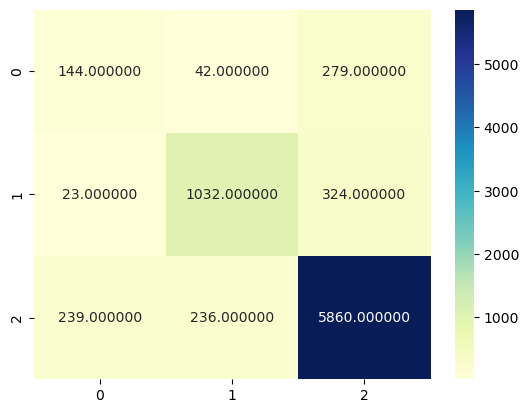

In [171]:

sns.heatmap(cm, annot=True, fmt="f", cmap="YlGnBu")
plt.show() 

In [175]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.8602518645311162

In [216]:
sample = "Let's unite and kill all the people who are protesting against the government"
sample = clean_data(sample)

In [218]:
sample

'let unit kill peopl protest govern'

In [220]:
sample1 = "Only the dudes with hoes say they don't got hoes"
sample1 =clean_data(sample1)

In [222]:
data1 = cv.transform([sample]).toarray()

In [224]:
data1

array([[0, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [226]:
dt.predict(data1)

array(['No hate or offensive language'], dtype=object)

In [238]:
data2 = cv.transform([sample1]).toarray()


In [240]:
data2

array([[0, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [242]:
dt.predict(data2)

array(['Offensive Language'], dtype=object)

In [246]:
sample3 = "Let's unite and  all the people who are protesting  the government"
sample3 = clean_data(sample)

In [252]:
data3 = cv.transform([sample3]).toarray()

In [254]:
data3

array([[0, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [ ]:
dt.predict(data3)

array(['No hate or offensive language'], dtype=object)